In [1]:
from langgraph.graph import StateGraph, START, END
from  langchain_core.messages import HumanMessage, SystemMessage
from pydantic import BaseModel, Field
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
load_dotenv()

/Users/rahultiwari/Documents/aziz_ai_engineering/ai-env/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


True

In [2]:
llm = ChatOpenAI(model="gpt-4o-mini")


In [3]:
# state definations
from typing import TypedDict, Literal

class SentimentState(TypedDict):
    original_tweet: str
    sentiment: str
    confidence: float
    response_tweet: str


In [5]:
class SentimentAnalysis(BaseModel):
    sentiment: Literal["positive", "negative"] = Field(description="The sentiment classification either positive or negative")
    confidence: float = Field(ge=0, le=1.0, description="Confidence score from 0.0 to 1.0")
    reason: str = Field(description="Brief explanation")

In [7]:
# node 1 

def analyze_sentiment(state: SentimentState):
    tweet = state["original_tweet"]
    messages = [
        SystemMessage("Analyze sentiment and provide the structured output. Use 0 to 1.0 scale for confidence. lower is negative and higher is positive"),
        HumanMessage(tweet)
    ]
    structured_llm = llm.with_structured_output(SentimentAnalysis)

    analysis = structured_llm.invoke(messages)
    return {'sentiment': analysis.sentiment,
            'confidence': analysis.confidence}






def generate_postive_response(state: SentimentState):
    
    print(f"current state in positive respone node: {state}")

    messages = [
        SystemMessage(f"""Generate a warm response to this positive tweet under 280 chars.
                      Confidence: {state['confidence']}. High confidence means be enthusiastic otherwise be friendly."""),
        HumanMessage(state['original_tweet'])
    ]

    response = llm.invoke(messages)

    return {'response_tweet': response.content.strip()}


def generate_negative_response(state: SentimentState):
    print(f"current state in negative respone node: {state}")

    messages = [
        SystemMessage(f"""Generate and empathetic response to this negative tweet under 280 chars.
                      If Confidence {state['confidence']} is very low then be empathetic otherwise 
                      be understanding."""),
        HumanMessage(state['original_tweet'])
    ]

    response = llm.invoke(messages)

    return {'response_tweet': response.content.strip()}

In [9]:
def route_by_sentiment(state: SentimentState):
    if state['sentiment'] == 'positive':
        return "positive_response"
    
    else:
        return "negative_response"

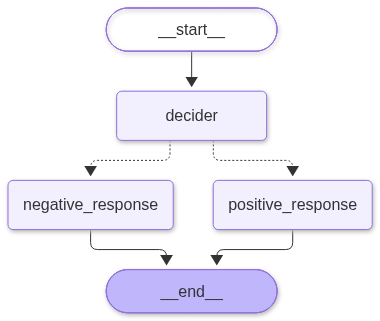

In [11]:
builder = StateGraph(SentimentState)
builder.add_node("decider", analyze_sentiment)
builder.add_node("positive_response", generate_postive_response)
builder.add_node("negative_response", generate_negative_response)

builder.add_edge(START, "decider")
builder.add_conditional_edges("decider",route_by_sentiment,["positive_response", "negative_response"])
builder.add_edge("positive_response", END)
builder.add_edge("negative_response", END)
graph = builder.compile()
graph



In [14]:
tweet = "very good product"
result = graph.invoke({'original_tweet': tweet})


current state in positive respone node: {'original_tweet': 'very good product', 'sentiment': 'positive', 'confidence': 0.9}


In [15]:
result

{'original_tweet': 'very good product',
 'sentiment': 'positive',
 'confidence': 0.9,
 'response_tweet': "Thanks so much for your kind words! We're thrilled to hear that you're enjoying the product. Your support means the world to us! 🌟 If you have any feedback or questions, we’re here for you! 😊"}

In [ ]:
# llm.with_structured_output(SentimentAnalysis).invoke('tell me my review is positive or negative : very bad product')

SentimentAnalysis(sentiment='negative', confidence=0.95, reason="The phrase 'very bad product' clearly expresses dissatisfaction and disappointment with the product.")

In [ ]:
# llm.invoke('tell me my review is positive or negative : very bad product')

AIMessage(content='Your review is negative. It expresses dissatisfaction with the product, indicating it did not meet your expectations.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 20, 'prompt_tokens': 19, 'total_tokens': 39, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_fe5dc95ec4', 'id': 'chatcmpl-EnwWFQ16ZLvyatHSl9UotN2jI49v9', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a2106a-35de-7261-aec0-55e036343282-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 19, 'output_tokens': 20, 'total_tokens': 39, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'rea